# 2. Transfer learning i poređenje tri arhitekture

Ovaj notebook prikazuje **kako je trening urađen** i **upoređuje tri arhitekture**
(MobileNetV3-Large, ResNet50, EfficientNetB0) po metrikama koje je tražila
profesorica: accuracy, precision, recall, F1 i matrica konfuzije.

Sam trening se pokreće iz terminala (`./run_varroa.sh`, oko sat vremena); ovde se
čitaju njegovi rezultati iz `runs/varroa_*/`.

**Šta je naš kod, a šta biblioteka:** arhitekture mreža i njihove ImageNet težine
dolaze iz biblioteke `torchvision` i nisu menjane. Naš kod (`src/models.py`,
`src/train.py`) zamenjuje poslednji sloj, bira koji se slojevi treniraju, priprema
slike i vodi trening.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
pd.set_option("display.max_colwidth", 80)

## 2.1 Transfer learning u tri poteza

1. učita se mreža istrenirana na ImageNet-u (1,28 miliona slika)
2. poslednji sloj (1.000 klasa) zameni se novim sa 2 izlaza: `zdrava`, `varoa`
3. faza 1: telo zamrznuto, trenira se samo nova glava (15 epoha);
   faza 2: odmrzne se poslednji blok tela i trenira sa 100× manjom stopom učenja (10 epoha)

In [2]:
from src.models import build_model, freeze_backbone, unfreeze_last_block, count_parameters
rows = []
for arch in ["mobilenet_v3_large", "resnet50", "efficientnet_b0"]:
    model, _, _ = build_model(arch, 2, "letterbox")
    total = count_parameters(model)[0]
    freeze_backbone(model, arch); faza1 = count_parameters(model)[1]
    unfreeze_last_block(model, arch); faza2 = count_parameters(model)[1]
    rows.append({"arhitektura": arch, "ukupno": total, "trenira se u fazi 1": faza1, "u fazi 2": faza2})
pd.DataFrame(rows)

,arhitektura,ukupno,trenira se u fazi 1,u fazi 2
0,mobilenet_v3_large,4204594,1232642,2185522
1,resnet50,23512130,4098,14968834
2,efficientnet_b0,4010110,2562,1131954


## 2.2 Priprema slike i augmentacija

Slike su uspravne (160×280). Umesto isecanja centralnog kvadrata (koje bi odseklo glavu
i zadak) cela slika se smanji i dopuni do kvadrata — *letterbox*. Tokom treninga se
svaka slika nasumično rotira, preslika, pomera i menja joj se osvetljenje:

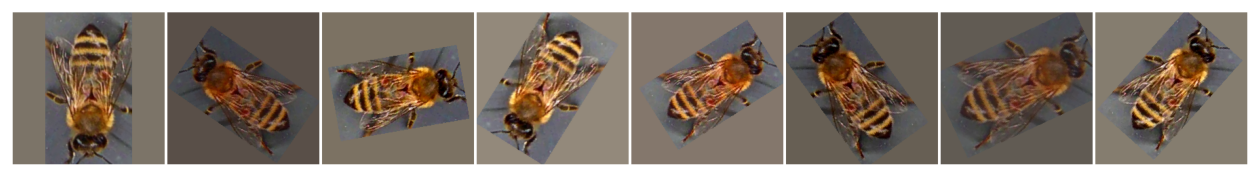

In [3]:
plt.figure(figsize=(16, 3)); plt.imshow(Image.open("report/figures/varroa_augmentation.png")); plt.axis("off");

## 2.3 Krive učenja

Vertikalna linija je prelaz u fine-tuning. Val skup su snimci koje model ne vidi u treningu.

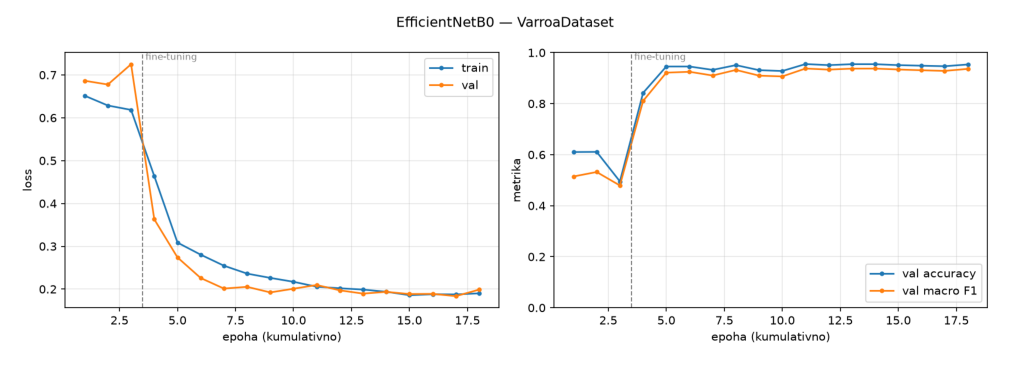

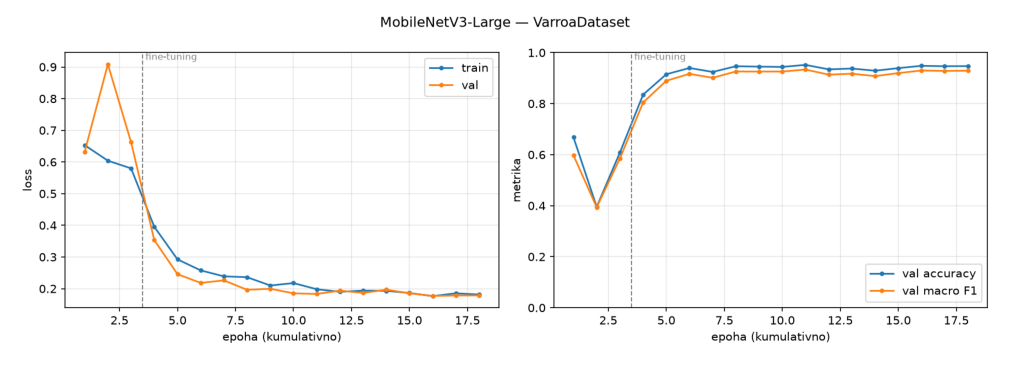

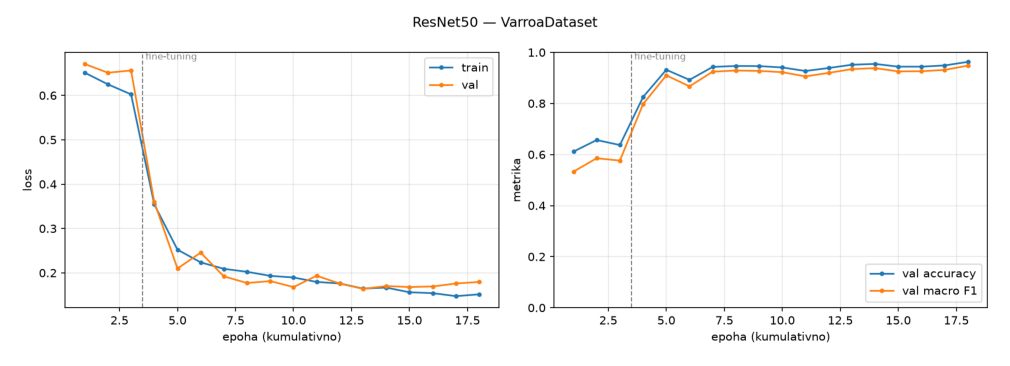

In [4]:
RUNS = ROOT / "runs"
runs = sorted(p.name for p in RUNS.glob("varroa_*") if (p / "metrics.json").exists())
for run in runs:
    plt.figure(figsize=(13, 4.5)); plt.imshow(Image.open(RUNS / run / "learning_curves.png")); plt.axis("off"); plt.show()

## 2.4 Poređenje na test skupu (3.408 slika, 2 snimka koje model nikad nije video)

In [5]:
metrics = {r: json.loads((RUNS / r / "metrics.json").read_text()) for r in runs}
tabela = pd.DataFrame([{
    "arhitektura": m["arch_display"],
    "accuracy": m["accuracy"],
    "precision (macro)": m["macro_precision"],
    "recall (macro)": m["macro_recall"],
    "F1 (macro)": m["macro_f1"],
    "recall varoa": m["varroa_recall"],
    "ROC AUC": m.get("roc_auc"),
    "parametara (M)": round(m["total_params"] / 1e6, 1),
    "trening (min)": round(m["train_seconds"] / 60, 1),
} for m in metrics.values()]).sort_values("F1 (macro)", ascending=False)
tabela

,arhitektura,accuracy,precision (macro),recall (macro),F1 (macro),recall varoa,ROC AUC,parametara (M),trening (min)
2,ResNet50,0.9310,0.9152,0.9117,0.9134,0.8684,0.9753,23.5,40.0
0,EfficientNetB0,0.9217,0.9054,0.8970,0.9011,0.8418,0.9644,4.0,24.8
1,MobileNetV3-Large,0.9199,0.8964,0.9063,0.9011,0.8758,0.9662,4.2,20.4


### Metrike po klasi

In [6]:
for m in metrics.values():
    print(m["arch_display"])
    display(pd.DataFrame(m["per_class"]).T)

EfficientNetB0


,precision,recall,f1,support
zdrava,0.9403,0.9521,0.9462,2466.0
varoa,0.8705,0.8418,0.8559,942.0


MobileNetV3-Large


,precision,recall,f1,support
zdrava,0.9518,0.9367,0.9442,2466.0
varoa,0.8410,0.8758,0.8580,942.0


ResNet50


,precision,recall,f1,support
zdrava,0.9500,0.9550,0.9525,2466.0
varoa,0.8805,0.8684,0.8744,942.0


### Matrice konfuzije

Red = stvarna klasa, kolona = šta je model rekao. Najskuplja greška za pčelara je
**zaražena pčela proglašena zdravom** (donji levi ugao).

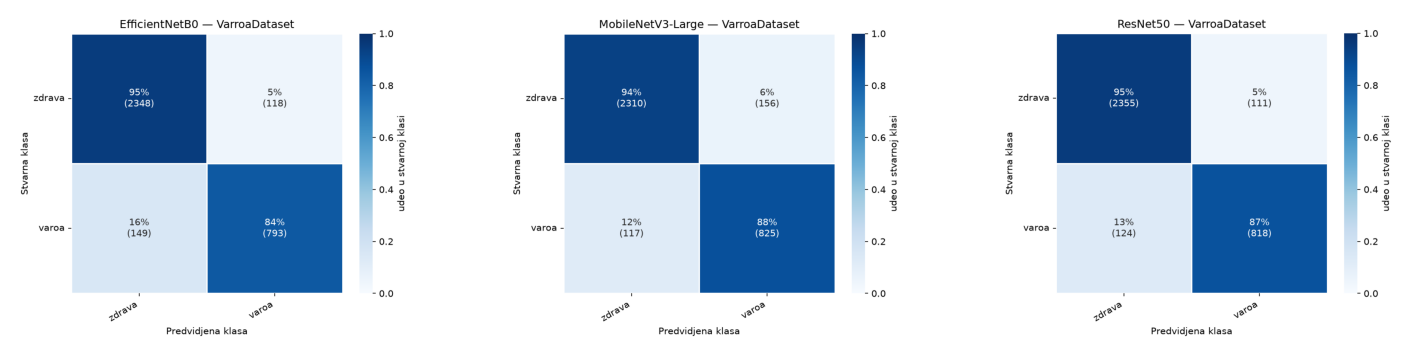

In [7]:
fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 5))
for ax, run in zip(np.atleast_1d(axes), runs):
    ax.imshow(Image.open(RUNS / run / "confusion_matrix.png")); ax.axis("off")

### Rezultat po test snimku

Test skup ima dva snimka sa vrlo različitim udelom zaraženih pčela (48% i 15%).
Ako bi model radio dobro samo na jednom, to bi ukazivalo na zavisnost od uslova snimanja.

In [8]:
pd.DataFrame({m["arch_display"]: {v: d["accuracy"] for v, d in m["per_video"].items()}
              for m in metrics.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
2017-09-01_10-54-26,0.8842,0.8826,0.9061
2017-10-17_1-39-36,0.9441,0.9423,0.9460


### Oznaka 1 (grinja jasno vidljiva) i oznaka 3 (delimično skrivena)

Recall na varoi, odvojeno po originalnoj oznaci autora. Očekuje se da je oznaka 3 teža.

In [9]:
pd.DataFrame({m["arch_display"]: m["varroa_recall_by_raw_label"] for m in metrics.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
1,0.9239,0.9470,0.9484
3,0.5485,0.6214,0.5825
